# A month of Australian racing closing lines

What this notebook does, top to bottom:

1. reads the fixed **September 2026 edition** of the PuntersEdge market report — no key needed — and charts each bookmaker's book percentage at the jump;
2. pulls a week of Australian thoroughbred **closing lines** from the permanent archive as CSV (Standard plan and above, 20 credits for the call);
3. recomputes each bookmaker's best-price share and the open-to-close movement locally, so you can see the counting rule rather than trust a table;
4. measures the **closing-line value** of every opening price, by bookmaker;
5. scores three bets with `POST /v1/racing/clv` (Plus and above — on a smaller plan you will see the 403 and the upgrade link the API returns).

You need `requests`, `pandas` and `matplotlib`, and a key in `PUNTERSEDGE_API_KEY` for steps 2–5.
[Get a free key](https://puntersedge.online/api?utm_source=github_examples&utm_medium=notebook#signup) (no card); the archive pull needs Standard.

CLV measures a price against the market's final view of the race, not against the result. Nothing here is a betting strategy.
18+. Gambling can be addictive — Gambling Help 1800 858 858.


In [1]:
import io, os, json
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

API = "https://api.puntersedge.online"
SITE = "https://puntersedge.online"
KEY = os.environ.get("PUNTERSEDGE_API_KEY", "")
OUT = Path("docs") if Path("docs").is_dir() else Path("../docs")
OUT.mkdir(exist_ok=True)
GREEN, AMBER, INK, RED = "#0B5B38", "#E3A008", "#131C16", "#B3261E"

S = requests.Session()
S.headers["User-Agent"] = "puntersedge-examples-notebook/1.0"
if KEY:
    S.headers["X-API-Key"] = KEY
print("key present:", bool(KEY))

key present: True


## 1. The fixed monthly edition (no key)

`/market-report/<YYYY-MM>.json` is measured once after the month closes and never recomputed, so a number quoted from it stays put. The live page at `/market-report` refreshes daily; cite an edition when the figure must not move.

In [2]:
ed = requests.get(SITE + "/market-report/2026-09.json", timeout=60).json()
print(ed["edition"]["label"], "—", f'{ed["coverage"]["races_total"]:,} AU+NZ races,',
      len(ed["bookmakers_included"]), "bookmakers, measured", ed["measured_at"])
print("Attribution:", ed["cite"]["attribution"], "·", ed["cite"]["canonical"])
best = pd.DataFrame(ed["best_price_share"]["rows"])[["name", "closing_lines", "best_or_equal", "share_pct", "sole_best_pct"]]
print(ed["best_price_share"]["method"])
best

September 2026 — 6,962 AU+NZ races, 14 bookmakers, measured 2026-09-30T22:01:47Z
Attribution: Source: PuntersEdge Australian Racing Market Report, September 2026 edition · https://puntersedge.online/market-report/2026-09
For every runner in an Australian or New Zealand race that at least three served bookmakers held a closing line on (last observed price within 300 seconds of the jump), a bookmaker scores when its closing win price equals the highest of the group; its share is that count divided by its own closing lines, so equal-best counts for every bookmaker at that price and the column does not sum to 100.


,name,closing_lines,best_or_equal,share_pct,sole_best_pct
0,PointsBet,51309,21244,41.4,14.1
1,BetRight,50506,18368,36.4,11.9
2,TAB,48901,15834,32.4,6.7
3,Unibet,47160,11487,24.4,5.5
4,Sportsbet,24237,5748,23.7,8.1
5,BetGold,34923,7794,22.3,0.1
6,BoostBet,34944,7754,22.2,0.1
7,TABtouch,49881,9970,20.0,1.8
8,Betr,48283,8558,17.7,2.3
9,NextBet (formerly PlayUp),48706,7758,15.9,1.9


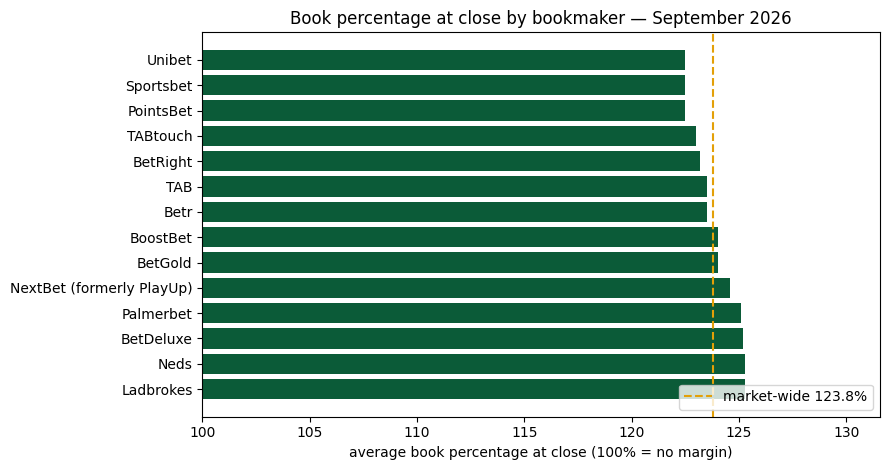

Book percentage is the sum of 1/price across the field at close, per race and bookmaker, counted only where the bookmaker priced the full field (its runner count equals the largest any served bookmaker priced in that race, fields of four or more) and averaged per bookmaker; market-wide is the average over every race-bookmaker pair.


In [3]:
over = pd.DataFrame(ed["overround"]["rows"]).sort_values("avg_pct", ascending=False)
mw = ed["overround"]["market_wide"]["avg_pct"]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(over["name"], over["avg_pct"], color=GREEN)
ax.axvline(mw, color=AMBER, ls="--", label=f"market-wide {mw}%")
ax.set_xlim(left=100)
ax.set_xlabel("average book percentage at close (100% = no margin)")
ax.set_title(f'Book percentage at close by bookmaker — {ed["edition"]["label"]}')
ax.legend(loc="lower right")
plt.tight_layout(); fig.savefig(OUT / "nb-overround.png", dpi=110); plt.show()
print(ed["overround"]["method"])

In [4]:
fav = pd.DataFrame(ed["favourites"]["rows"])[["label", "races", "wins", "strike_pct", "placed_pct", "avg_fav_price"]]
print(ed["favourites"]["method"])
fav

The favourite is the runner with the lowest median closing price across served bookmakers (at least two quotes) in each race with a final result; strike rate is the share of those races the favourite won, and placed is the share where it finished in the first three.


,label,races,wins,strike_pct,placed_pct,avg_fav_price
0,Greyhound,3774,1640,43.5,75.9,2.18
1,Harness,1343,557,41.5,71.7,2.32
2,Thoroughbred,1435,512,35.7,67.8,2.82


## 2. A week of closing lines from the archive (Standard and above)

One row per race, runner and bookmaker: the earliest archived price ("open", up to 60 minutes out), the last one ("close"), whether that close was observed inside 300 seconds of the jump (`is_closing_line`), and the finish position once the race is final. `format=csv` streams a flat table; the call costs 20 credits.

In [5]:
FROM, TO = "2026-09-25", "2026-09-30"
df = pd.DataFrame()
if not KEY:
    print("No PUNTERSEDGE_API_KEY in the environment — skipping the archive pull.")
else:
    r = S.get(API + "/v1/racing/closing-lines",
              params={"from": FROM, "to": TO, "category": "horse", "country": "AU",
                      "resulted_only": "true", "format": "csv", "limit": 50000}, timeout=120)
    print("HTTP", r.status_code, "· cost header:", r.headers.get("X-Credits-Cost") or "n/a",
          "· remaining:", r.headers.get("X-Credits-Remaining") or "n/a")
    if r.ok:
        df = pd.read_csv(io.StringIO(r.text))
        print(f"{len(df):,} rows · {df['race_id'].nunique()} races · {df['bookmaker_key'].nunique()} bookmakers")
        print(list(df.columns))
    else:
        print(r.text[:400])

HTTP 200 · cost header: n/a · remaining: n/a
27,108 rows · 264 races · 14 bookmakers
['race_id', 'start_time', 'meeting_date_aet', 'venue', 'race_number', 'category', 'country', 'runner_key', 'runner_name', 'runner_number', 'bookmaker_key', 'open_win_price', 'open_secs_to_jump', 'open_is_baseline', 'close_win_price', 'close_lay_price', 'close_secs_to_jump', 'is_closing_line', 'points_observed', 'finish_position', 'result_status', 'venue_split_suspect', 'venue_split_peer_race_id', 'name_fragment_suspect', 'venue_id', 'venue_site', 'runner_ref', 'horse_ref', 'scratched', 'open_place_price', 'close_place_price', 'scratched_at']


In [6]:
# Best-or-equal share at the jump, recomputed locally with the report's own rule:
# a runner needs three or more closing lines; a bookmaker scores when its close equals the best.
if len(df):
    w = df[df["is_closing_line"].astype(str).str.lower().eq("true") & (df["close_win_price"] > 1)].copy()
    g = w.groupby(["race_id", "runner_key"])["close_win_price"]
    w["best"] = g.transform("max")
    w["books"] = g.transform("size")
    w = w[w["books"] >= 3]
    share = (w.assign(best_or_equal=w["close_win_price"] >= w["best"])
               .groupby("bookmaker_key")
               .agg(closing_lines=("close_win_price", "size"), best_or_equal=("best_or_equal", "sum")))
    share["share_pct"] = (100 * share["best_or_equal"] / share["closing_lines"]).round(1)
    display(share.sort_values("share_pct", ascending=False))
else:
    w = pd.DataFrame()

,closing_lines,best_or_equal,share_pct
bookmaker_key,,,
pointsbetau,2318,1095,47.2
betright,2320,997,43.0
unibet,2124,584,27.5
tabtouch,2178,496,22.8
tab,2123,448,21.1
playup,2094,416,19.9
betr_au,2094,387,18.5
sportsbet,1323,239,18.1
betgold,2201,358,16.3


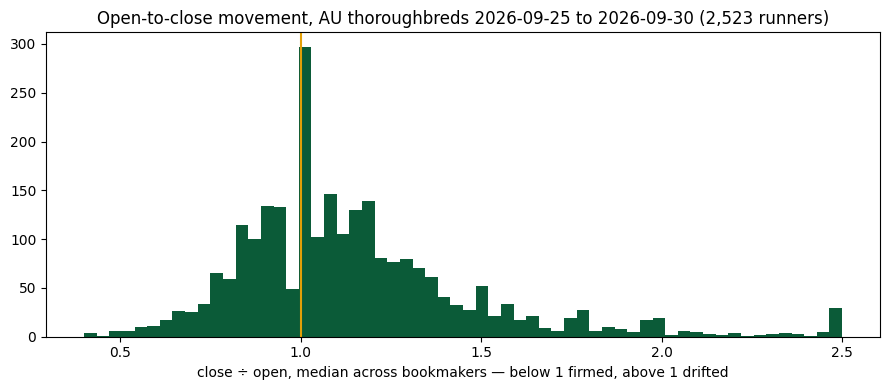

Five biggest steamers


,venue,race_number,runner_name,open,close,ratio,books,finish
4374,Coleraine,7,Stormsarrived,151.0,46.0,0.33,11,9.0
3312,Grafton,1,Nature Boy,18.0,7.0,0.39,12,4.0
4101,Longreach,7,Spanish Blaze,16.0,6.5,0.41,9,7.0
4022,Balaklava,3,Out Ontario,23.0,10.0,0.43,13,4.0
4367,Coleraine,7,Mangione,151.0,67.0,0.46,10,1.0


Five biggest drifters


,venue,race_number,runner_name,open,close,ratio,books,finish
1954,Ballarat,3,Burrow,26.0,126.0,4.67,13,10.0
3610,Sunshine Coast,2,Purposely,41.0,201.0,3.94,11,8.0
3392,Kilmore,8,Bancoora,19.0,61.0,3.21,13,7.0
580,DUBBO,2,Bitta Bon Magic,21.0,67.0,3.19,10,6.0
846,Ballarat,6,Getsmybloodrussian,26.0,81.0,3.12,13,7.0


In [7]:
# Open-to-close movement: the median across bookmakers of close ÷ open, per runner.
if len(w):
    m = w[w["open_win_price"] > 1].copy()
    m["ratio"] = m["close_win_price"] / m["open_win_price"]
    agg = (m.groupby(["race_id", "venue", "race_number", "runner_name"])
             .agg(ratio=("ratio", "median"), books=("ratio", "size"),
                  open=("open_win_price", "median"), close=("close_win_price", "median"),
                  finish=("finish_position", "min"))
             .reset_index())
    agg = agg[agg["books"] >= 3]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(agg["ratio"].clip(0.4, 2.5), bins=60, color=GREEN)
    ax.axvline(1, color=AMBER)
    ax.set_xlabel("close ÷ open, median across bookmakers — below 1 firmed, above 1 drifted")
    ax.set_title(f"Open-to-close movement, AU thoroughbreds {FROM} to {TO} ({len(agg):,} runners)")
    plt.tight_layout(); fig.savefig(OUT / "nb-open-to-close.png", dpi=110); plt.show()
    cols = ["venue", "race_number", "runner_name", "open", "close", "ratio", "books", "finish"]
    print("Five biggest steamers"); display(agg.nsmallest(5, "ratio")[cols].round(2))
    print("Five biggest drifters"); display(agg.nlargest(5, "ratio")[cols].round(2))

## 3. Closing-line value of the opening price, by bookmaker

CLV asks one question of a price: was it longer than the market's final view of that runner? Here the "bet" is hypothetical — every opening price, at every bookmaker, held to the jump — and the answer is measured, not modelled: `open ÷ close − 1`, averaged per bookmaker. A positive mean says that book's early prices were, on average, longer than its own close; it says nothing about whether those runners won.

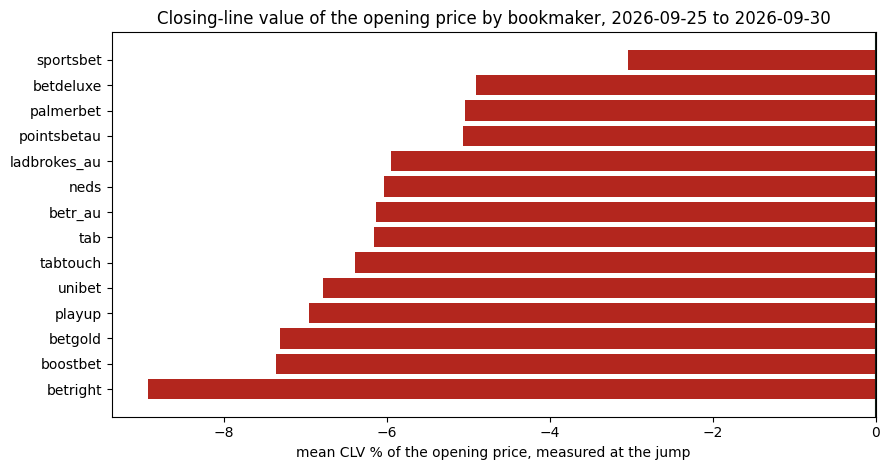

,mean,median,size
bookmaker_key,,,
sportsbet,-3.04,-7.14,1323
betdeluxe,-4.90,-8.63,656
palmerbet,-5.04,-8.00,671
pointsbetau,-5.07,-7.14,2318
ladbrokes_au,-5.95,-7.69,2367
neds,-6.03,-7.69,2378
betr_au,-6.13,-8.14,2094
tab,-6.16,-7.69,2123
tabtouch,-6.39,-8.00,2178


In [8]:
if len(w):
    c = w[w["open_win_price"] > 1].copy()
    c["clv_pct"] = (c["open_win_price"] / c["close_win_price"] - 1) * 100
    by = c.groupby("bookmaker_key")["clv_pct"].agg(["mean", "median", "size"]).round(2).sort_values("mean")
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.barh(by.index, by["mean"], color=[GREEN if v >= 0 else RED for v in by["mean"]])
    ax.axvline(0, color=INK)
    ax.set_xlabel("mean CLV % of the opening price, measured at the jump")
    ax.set_title(f"Closing-line value of the opening price by bookmaker, {FROM} to {TO}")
    plt.tight_layout(); fig.savefig(OUT / "nb-clv-by-book.png", dpi=110); plt.show()
    display(by.sort_values("mean", ascending=False))

## 4. Score your own bets: `POST /v1/racing/clv` (Plus and above)

Send up to 200 bets — a race (by `race_id`, or venue + date + race number), a runner, the price you took and optionally the bookmaker — and get back each bet's closing line, its CLV, whether it beat the close, and the result once the race is final. 5 credits a request. On a plan below Plus the API answers 403 and names the tier that has it, with a link; the cell prints that instead of failing.

In [9]:
if len(w):
    resulted = w.dropna(subset=["finish_position"])
    sample = resulted.sample(3, random_state=7) if len(resulted) >= 3 else resulted.head(3)
    bets = [{"ref": f"bet-{i + 1}", "race_id": row.race_id, "runner_name": row.runner_name,
             "bookmaker": row.bookmaker_key, "price": float(row.open_win_price), "stake": 10}
            for i, row in enumerate(sample.itertuples())]
    r = S.post(API + "/v1/racing/clv", json={"bets": bets, "reference": "best"}, timeout=60)
    print("HTTP", r.status_code)
    body = r.json()
    if r.ok:
        display(pd.DataFrame(body.get("bets", [])))
        print({k: v for k, v in body.items() if k != "bets"})
    else:
        print(body.get("title") or body.get("detail"))
        print("Upgrade link from the response header:", r.headers.get("X-Upgrade-Url"))

HTTP 403
Closing-line value scoring is available on Plus, Business, Platform, Scale and Enterprise plans only. Upgrade: https://puntersedge.online/api/pricing?plan=plus&utm_source=api_403#plan-plus
Upgrade link from the response header: https://puntersedge.online/api/pricing?plan=plus&utm_source=api_403#plan-plus


## Cite and go further

- Source for section 1: PuntersEdge Australian Racing Market Report, September 2026 edition — https://puntersedge.online/market-report/2026-09 (free to reuse with attribution).
- The archive endpoint: https://puntersedge.online/developers/api-reference/racing-closing-lines · CLV scoring: https://puntersedge.online/developers/api-reference/racing-clv · every endpoint in plain English: https://puntersedge.online/endpoints
- [Get a free API key](https://puntersedge.online/api?utm_source=github_examples&utm_medium=notebook#signup). Plans and what each unlocks: https://puntersedge.online/api/pricing

Data is for informational and analytical use only. 18+. Gambling Help 1800 858 858.
